<a href="https://colab.research.google.com/github/MiikanGod/Classification/blob/main/lasifikasi_MultiLabel_(Mental_Health_Dataset).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# 1. IMPORT LIBRARY & UPLOAD DATASET
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, hamming_loss
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import LabelEncoder

from google.colab import files

print('--- UPLOAD FILE Mental Health Dataset.csv ---')
uploaded = files.upload()

# Load Dataset
df_mh = pd.read_csv('Mental Health Dataset.csv')
print(
    f'\nUkuran Dataset Awal: {df_mh.shape[0]} baris, {df_mh.shape[1]} kolom\n'
)
print('5 Baris Pertama Dataset:')
print(df_mh.head())

--- UPLOAD FILE Mental Health Dataset.csv ---


Saving Mental Health Dataset.csv to Mental Health Dataset.csv

Ukuran Dataset Awal: 292364 baris, 17 kolom

5 Baris Pertama Dataset:
         Timestamp  Gender        Country Occupation self_employed  \
0  8/27/2014 11:29  Female  United States  Corporate           NaN   
1  8/27/2014 11:31  Female  United States  Corporate           NaN   
2  8/27/2014 11:32  Female  United States  Corporate           NaN   
3  8/27/2014 11:37  Female  United States  Corporate            No   
4  8/27/2014 11:43  Female  United States  Corporate            No   

  family_history treatment Days_Indoors Growing_Stress Changes_Habits  \
0             No       Yes    1-14 days            Yes             No   
1            Yes       Yes    1-14 days            Yes             No   
2            Yes       Yes    1-14 days            Yes             No   
3            Yes       Yes    1-14 days            Yes             No   
4            Yes       Yes    1-14 days            Yes             No   

  Menta

In [2]:
# ==============================================================================
# 2. PREPROCESSING & FEATURE ENGINEERING
# ==============================================================================
# Menghapus baris/kolom dengan missing value jika ada
df_mh = df_mh.dropna()

# Menentukan Kolom Target Multi-Label & Kolom Fitur
# (Contoh target kondisi mental yang diprediksi secara bersamaan)
target_cols = [
    'Growing_Stress',
    'Changes_Habits',
    'Mood_Swings',
    'Coping_Struggles',
]

# Memastikan kolom target ada dalam dataset
target_cols = [c for c in target_cols if c in df_mh.columns]
feature_cols = [c for c in df_mh.columns if c not in target_cols]

print(f'\nTarget Multi-Label yang diprediksi ({len(target_cols)} label):')
print(target_cols)

# Melakukan Encoding Kategorikal (One-Hot / Label Encoding) pada seluruh fitur dan target
label_encoders = {}

# Preprocessing Fitur (X)
X_df = df_mh[feature_cols].copy()
for col in X_df.columns:
  if X_df[col].dtype == 'object':
    le = LabelEncoder()
    X_df[col] = le.fit_transform(X_df[col].astype(str))
    label_encoders[col] = le

# Preprocessing Target Multi-Label (Y)
Y_df = df_mh[target_cols].copy()
for col in target_cols:
  if Y_df[col].dtype == 'object':
    le_t = LabelEncoder()
    Y_df[col] = le_t.fit_transform(Y_df[col].astype(str))
    label_encoders['target_' + col] = le_t

X = X_df.values
Y = Y_df.values

# Split Data (80% Train, 20% Test)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
print(f'\nJumlah Data Latih (Train): {X_train.shape[0]}')
print(f'Jumlah Data Uji (Test): {X_test.shape[0]}')


Target Multi-Label yang diprediksi (4 label):
['Growing_Stress', 'Changes_Habits', 'Mood_Swings', 'Coping_Struggles']

Jumlah Data Latih (Train): 229729
Jumlah Data Uji (Test): 57433


In [5]:
# ==============================================================================
# 3. MEMBANGUN & MELATIH MODEL MULTI-LABEL
# ==============================================================================
print('\nSedang melatih model Multi-Label Classifier (Random Forest)...')
base_model = RandomForestClassifier(n_estimators=100, random_state=42)
multi_label_model = MultiOutputClassifier(base_model, n_jobs=-1)

multi_label_model.fit(X_train, Y_train)
print('Pelatihan Model Multi-Label Selesai!')


Sedang melatih model Multi-Label Classifier (Random Forest)...
Pelatihan Model Multi-Label Selesai!


In [8]:
# ==============================================================================
# 4. EVALUASI MODEL MULTI-LABEL (PERBAIKAN)
# ==============================================================================
Y_pred = multi_label_model.predict(X_test)

# Metric 1: Exact Match Accuracy (Semua kolom label harus tepat sama)
exact_match_acc = np.mean(np.all(Y_test == Y_pred, axis=1))

# Metric 2: Hamming Loss (Rata-rata kesalahan prediksi per label)
h_loss = np.mean(Y_test != Y_pred)

print(
    f'\n========================================================================'
)
print(f' EXACT MATCH ACCURACY (ALL LABELS MATCH): {exact_match_acc * 100:.2f}%')
print(
    f' HAMMING LOSS (LABEL ERROR RATE)        : {h_loss:.4f}'
    f' ({(1 - h_loss) * 100:.2f}% Kebenaran Label)'
)
print(
    f'========================================================================\n'
)

# Evaluasi Laporan Per-Target Label
print('--- Laporan Performa Per Tiap Target Label ---')
for i, col_name in enumerate(target_cols):
  print(f'\n>>> Target: {col_name}')
  target_le = label_encoders.get('target_' + col_name)
  target_names = (
      [str(c) for c in target_le.classes_] if target_le else None
  )

  print(
      classification_report(
          Y_test[:, i],
          Y_pred[:, i],
          target_names=target_names,
          zero_division=0,
      )
  )


 EXACT MATCH ACCURACY (ALL LABELS MATCH): 55.48%
 HAMMING LOSS (LABEL ERROR RATE)        : 0.2798 (72.02% Kebenaran Label)

--- Laporan Performa Per Tiap Target Label ---

>>> Target: Growing_Stress
              precision    recall  f1-score   support

       Maybe       0.71      0.71      0.71     19739
          No       0.65      0.64      0.65     18248
         Yes       0.72      0.72      0.72     19446

    accuracy                           0.69     57433
   macro avg       0.69      0.69      0.69     57433
weighted avg       0.69      0.69      0.69     57433


>>> Target: Changes_Habits
              precision    recall  f1-score   support

       Maybe       0.69      0.67      0.68     18813
          No       0.74      0.76      0.75     17132
         Yes       0.75      0.75      0.75     21488

    accuracy                           0.73     57433
   macro avg       0.73      0.73      0.73     57433
weighted avg       0.73      0.73      0.73     57433


>>> Targe

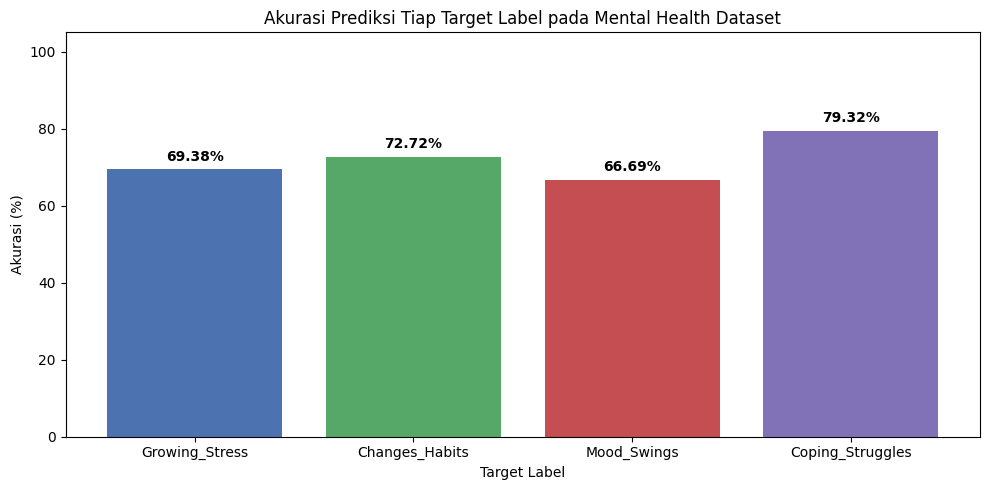

In [9]:
# ==============================================================================
# 5. VISUALISASI HASIL EVALUASI MULTI-LABEL
# ==============================================================================
label_accuracies = []
for i in range(len(target_cols)):
  acc_i = accuracy_score(Y_test[:, i], Y_pred[:, i])
  label_accuracies.append(acc_i * 100)

plt.figure(figsize=(10, 5))
bars = plt.bar(
    target_cols, label_accuracies, color=['#4C72B0', '#55A868', '#C44E52', '#8172B8']
)
plt.title('Akurasi Prediksi Tiap Target Label pada Mental Health Dataset')
plt.xlabel('Target Label')
plt.ylabel('Akurasi (%)')
plt.ylim(0, 105)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1.5,
      f'{yval:.2f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
  )

plt.tight_layout()
plt.show()